# Perfect vs gold OAP surface: vectorial Fresnel reflection

We compare the focus of a real **90° off-axis parabolic mirror** for two surfaces:

* a **perfect reflector** (ideal conductor), and
* a **gold coating** (complex refractive index), using **vectorial Fresnel
  reflection** with a proper $s/p$ decomposition.

**Reflected field.** For an incident field $\mathbf E_i$ with propagation direction
$\hat{\mathbf e}_i$, local normal $\hat{\mathbf n}$ and reflected direction
$\hat{\mathbf e}_r$, decompose into $s$ (perpendicular to the plane of incidence) and
$p$ (in it):
$$
\hat{\mathbf s}=\frac{\hat{\mathbf e}_i\times\hat{\mathbf n}}{|\hat{\mathbf e}_i\times\hat{\mathbf n}|},\qquad
\hat{\mathbf p}_i=\hat{\mathbf e}_i\times\hat{\mathbf s},\qquad
\hat{\mathbf p}_r=\hat{\mathbf e}_r\times\hat{\mathbf s},
$$
$$
\boxed{\;\mathbf E_r=r_s\,(\mathbf E_i\!\cdot\!\hat{\mathbf s})\,\hat{\mathbf s}
+r_p\,(\mathbf E_i\!\cdot\!\hat{\mathbf p}_i)\,\hat{\mathbf p}_r\;}
$$
This is the form you proposed, with two corrections that matter: the reflected
$p$-component lies along $\hat{\mathbf p}_r=\hat{\mathbf e}_r\times\hat{\mathbf s}$
(**not** $\hat{\mathbf e}_r$ itself — otherwise $\mathbf E_r$ would not be transverse
to the reflected ray), and the coefficients are the **reflection** Fresnel
coefficients $r_s,r_p$ (not transmission $t$). Setting $r_s=-1,\;r_p=+1$ recovers the
ideal-mirror formula $\mathbf E_r=-\mathbf E_i+2(\mathbf E_i\!\cdot\!\hat{\mathbf n})\hat{\mathbf n}$
(checked below).

**Preview of the result.** For this near-IR gold the two *intensity* images are almost
identical (gold is ~2% dimmer). The real difference is **polarization**: at 45° the
$s$–$p$ phase split ellipticises the focal field.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

# ---- system ----
F    = 7.5e-3        # parent focal length [m]
LAM  = 1030e-9       # wavelength [m]
APER = 12.7e-3       # clear aperture (sub-aperture) diameter [m]
K    = 2*np.pi/LAM
E_I  = np.array([0., 0., -1.])          # incident direction (down the parent axis)

# Gold complex refractive index near 1030 nm (Johnson & Christy, approximate).
# Swap in your own tabulated/ellipsometry value; results scale with it.
N_AU = 0.26 + 6.82j
print(f"gold n~tilde = {N_AU}   normal-incidence reflectivity "
      f"R0 = {abs((1-N_AU)/(1+N_AU))**2:.4f}")

def rotation_matrix(axis, ang):
    a = np.asarray(axis, float); a = a/np.linalg.norm(a)
    Kx = np.array([[0,-a[2],a[1]],[a[2],0,-a[0]],[-a[1],a[0],0]])
    return np.eye(3) + np.sin(ang)*Kx + (1-np.cos(ang))*(Kx@Kx)

def normal_parent(xp, yp):
    n = np.stack([-xp/(2*F), -yp/(2*F), np.ones_like(np.asarray(xp, float))], -1)
    return n/np.linalg.norm(n, axis=-1, keepdims=True)

gold n~tilde = (0.26+6.82j)   normal-incidence reflectivity R0 = 0.9784


## 1. Fresnel coefficients for gold

Air ($n_1=1$) to metal ($n_2=\tilde n$). With local incidence angle $\theta_i$ and
$\cos\theta_t=\sqrt{1-(n_1/n_2)^2\sin^2\theta_i}$ (complex, decaying branch):
$$
r_s=\frac{n_1\cos\theta_i-n_2\cos\theta_t}{n_1\cos\theta_i+n_2\cos\theta_t},\qquad
r_p=\frac{n_2\cos\theta_i-n_1\cos\theta_t}{n_2\cos\theta_i+n_1\cos\theta_t}.
$$
The plot marks the OAP's incidence band (≈30–55°). Note $R_s\neq R_p$ and, more
importantly, a growing **phase split** $\arg r_p-\arg r_s$ — that is what changes the
polarization.

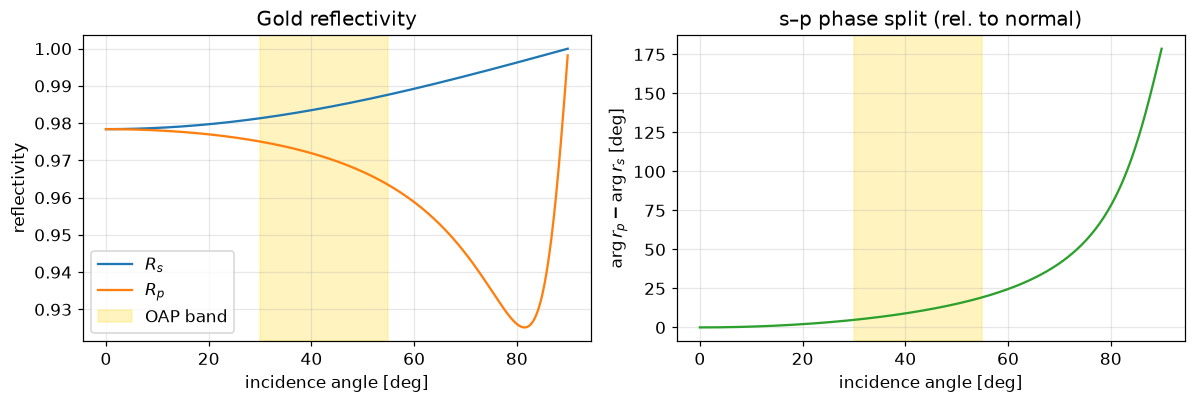

at 45 deg:  R_s=0.9847  R_p=0.9697  phase split =+11.8 deg


In [3]:
def fresnel_rs_rp(cos_i, n2, n1=1.0):
    sin_i2 = np.clip(1 - cos_i**2, 0, 1)
    cos_t = np.sqrt(1 - (n1/n2)**2 * sin_i2 + 0j)
    cos_t = np.where(cos_t.imag < 0, -cos_t, cos_t)      # decaying branch
    rs = (n1*cos_i - n2*cos_t)/(n1*cos_i + n2*cos_t)
    rp = (n2*cos_i - n1*cos_t)/(n2*cos_i + n1*cos_t)
    return rs, rp

ang = np.linspace(0, 89.9, 400)
rs, rp = fresnel_rs_rp(np.cos(np.deg2rad(ang)), N_AU)
# phase split referenced to normal incidence (removes the p-convention offset at 0 deg)
dphi = np.degrees(np.angle(rp) - np.angle(rs))
dphi = ((dphi - dphi[0] + 180) % 360) - 180

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(ang, np.abs(rs)**2, label='$R_s$'); ax[0].plot(ang, np.abs(rp)**2, label='$R_p$')
ax[0].axvspan(30, 55, color='gold', alpha=.25, label='OAP band')
ax[0].set_xlabel('incidence angle [deg]'); ax[0].set_ylabel('reflectivity'); ax[0].legend()
ax[0].set_title('Gold reflectivity'); ax[0].grid(alpha=.3)
ax[1].plot(ang, dphi, 'C2'); ax[1].axvspan(30, 55, color='gold', alpha=.25)
ax[1].set_xlabel('incidence angle [deg]'); ax[1].set_ylabel(r'$\arg r_p-\arg r_s$ [deg]')
ax[1].set_title('s–p phase split (rel. to normal)'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
rs45, rp45 = fresnel_rs_rp(np.cos(np.deg2rad(45)), N_AU)
print(f"at 45 deg:  R_s={abs(rs45)**2:.4f}  R_p={abs(rp45)**2:.4f}  "
      f"phase split ={np.degrees(np.angle(rp45)-np.angle(rs45))-180:+.1f} deg")

## 2. Vectorial reflection (and its perfect-conductor check)

We implement the boxed formula. The control confirms the ideal mirror is exactly the
perfect-conductor limit $r_s=-1,\;r_p=+1$.

In [4]:
def reflect_ideal(E, n):
    return -E + 2*np.sum(E*n, axis=-1, keepdims=True)*n

def reflect_fresnel(E, e_i, n, rs, rp):
    e_i = np.broadcast_to(e_i, n.shape)
    s = np.cross(e_i, n)
    smag = np.linalg.norm(s, axis=-1, keepdims=True)
    s = np.where(smag > 1e-12, s/np.where(smag > 0, smag, 1.0), np.array([0., 1., 0.]))
    e_r = e_i - 2*np.sum(e_i*n, axis=-1, keepdims=True)*n
    p_i = np.cross(e_i, s); p_r = np.cross(e_r, s)
    Es = np.sum(E*s, axis=-1, keepdims=True); Ep = np.sum(E*p_i, axis=-1, keepdims=True)
    return rs[..., None]*Es*s + rp[..., None]*Ep*p_r

# control: PEC limit == ideal mirror
rng = np.random.default_rng(0)
xp, yp = rng.uniform(-6e-3, 6e-3, 4000), rng.uniform(-6e-3, 6e-3, 4000)
n = normal_parent(xp, yp); e = np.broadcast_to(E_I, n.shape)
E0 = rng.standard_normal((4000,3)) + 1j*rng.standard_normal((4000,3))
E0 = E0 - np.sum(E0*e, -1, keepdims=True)*e             # make transverse
one = np.ones(4000)
diff = np.max(np.abs(reflect_ideal(E0, n)
              - reflect_fresnel(E0, E_I, n, -one+0j, one+0j)))
print("control  PEC Fresnel vs ideal mirror: max abs diff =", diff)

control  PEC Fresnel vs ideal mirror: max abs diff = 2.482534153247273e-15


## 3. The real 90° off-axis geometry

A 90° OAP is the piece of the parent centred where the surface normal folds an axial
ray by 90°. Reflecting $\hat{\mathbf e}_i=-\hat{\mathbf z}$ to $+\hat{\mathbf x}$ needs
$\hat{\mathbf e}_r\!\cdot\!\hat{\mathbf z}=0$, i.e. $\cos\theta=\tfrac{4f^2-\rho^2}{4f^2+\rho^2}=0$,
so the sub-aperture is centred at **parent radius $\rho_0=2f$** (off-axis distance
$=15$ mm) and the reflected focal length is $R=f+\rho_0^2/4f=2f=15$ mm — matching the
commercial numbers. The illuminated patch sees incidence angles ≈ 45° ± spread.

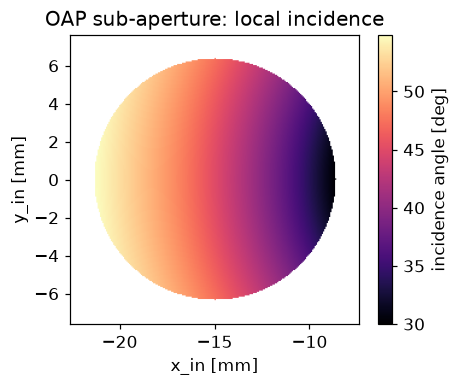

incidence across sub-aperture: 30.0–54.9 deg (mean 45.0)


In [5]:
def intersect(Xin, Yin, zin, R, t):
    Rt = R.T; d = Rt @ E_I
    rin = np.stack([Xin, Yin, np.full_like(Xin, zin)], -1)
    a = (rin - t) @ Rt.T
    ax, ay, az = a[...,0], a[...,1], a[...,2]; dx, dy, dz = d
    A = (dx**2+dy**2)/(4*F); B = 2*(ax*dx+ay*dy)/(4*F) - dz; C = (ax**2+ay**2)/(4*F) - az
    if abs(A) < 1e-14:
        s = -C/B
    else:
        disc = np.sqrt(np.maximum(B**2-4*A*C, 0.0))
        s1 = (-B-disc)/(2*A); s2 = (-B+disc)/(2*A)
        s = np.where((s1>0) & ((s1<s2)|(s2<=0)), s1, s2)
    r_p = a + s[...,None]*d
    return r_p[...,0], r_p[...,1], rin + s[...,None]*E_I

X_OFF = -2*F      # off-axis centre -> +x fold
pix, zin = 240, 0.05
Lp = 2.4*(APER/2)
xi = (np.arange(pix)-pix/2)*(Lp/pix)
Xin = X_OFF + np.meshgrid(xi, xi, indexing='xy')[0]
Yin = np.meshgrid(xi, xi, indexing='xy')[1]
xp, yp, r_m = intersect(Xin, Yin, zin, np.eye(3), np.zeros(3))
inside = ((xp-X_OFF)**2 + yp**2) <= (APER/2)**2
n_lab = normal_parent(xp, yp)
inc = np.degrees(np.arccos(np.abs(np.sum(E_I*n_lab, -1))))

plt.figure(figsize=(4.4,3.6))
im = plt.imshow(np.where(inside, inc, np.nan), origin='lower',
                extent=[(X_OFF-Lp/2)*1e3,(X_OFF+Lp/2)*1e3,-Lp/2*1e3,Lp/2*1e3], cmap='magma')
plt.colorbar(im, label='incidence angle [deg]')
plt.xlabel('x_in [mm]'); plt.ylabel('y_in [mm]'); plt.title('OAP sub-aperture: local incidence')
plt.tight_layout(); plt.show()
print(f"incidence across sub-aperture: {inc[inside].min():.1f}–{inc[inside].max():.1f} deg "
      f"(mean {inc[inside].mean():.1f})")

## 4. Focus for either surface

Same exact Debye machinery as the tolerancing notebook (energy-conserving flux
Jacobian, least-squares focus, non-uniform Debye sum), with a swappable reflection
model. Perfect-surface control: focuses to the parent focus $(0,0,f)$.

In [6]:
def output_basis(er_in):
    u = er_in.mean(0); u /= np.linalg.norm(u)
    ref = np.array([0,0,1.]) if abs(u[2])<0.9 else np.array([1.,0,0])
    v = ref - np.dot(ref,u)*u; v /= np.linalg.norm(v); w = np.cross(u,v)
    return u, v, w

def oap_focus(surface, pol=(1,1,0), Lout=18e-6, Nout=150, sig=3.0e-3):
    xp, yp, r_m = intersect(Xin, Yin, zin, np.eye(3), np.zeros(3))
    ins = ((xp-X_OFF)**2 + yp**2) <= (APER/2)**2
    n = normal_parent(xp, yp)
    cos_i = np.abs(np.sum(E_I*n, -1))
    e_r = E_I - 2*np.sum(E_I*n, -1, keepdims=True)*n
    Ein = np.exp(-((Xin-X_OFF)**2 + Yin**2)/sig**2).astype(complex)
    p = np.asarray(pol, complex); p = p/np.linalg.norm(p)
    E_i_vec = Ein[...,None]*p
    if surface == 'perfect':
        E_r = reflect_ideal(E_i_vec, n)
    else:
        rs, rp = fresnel_rs_rp(cos_i, N_AU)
        E_r = reflect_fresnel(E_i_vec, E_I, n, rs, rp)
    u,v,w = output_basis(e_r[ins])
    kv = K*(e_r@v); kw = K*(e_r@w); ku = K*(e_r@u)
    dkv_dy,dkv_dx = np.gradient(kv, xi, xi); dkw_dy,dkw_dx = np.gradient(kw, xi, xi)
    J = np.abs(dkv_dx*dkw_dy - dkv_dy*dkw_dx)/(K*np.maximum(ku,1e-9))
    wt = np.sqrt(np.maximum(J,0.0))
    er_in, rm_in = e_r[ins], r_m[ins]
    P = np.eye(3) - er_in[:,:,None]*er_in[:,None,:]
    Fpt = np.linalg.solve(P.sum(0), np.einsum('nij,nj->i', P, rm_in))
    L = np.sum((r_m-np.array([0,0,zin]))*E_I,-1) + np.sum(e_r*(Fpt-r_m),-1)
    phi = K*(L - L[ins].mean())
    dA = (Lp/pix)**2
    a = (E_r[ins]*(wt[ins]*np.exp(1j*phi[ins]))[:,None])*dA
    vax = (np.arange(Nout)-Nout/2)*(Lout/Nout)
    Mv = np.exp(1j*np.outer(vax, kv[ins])); Mw = np.exp(1j*np.outer(vax, kw[ins]))
    tr = lambda c: ((Mv*c[None,:])@Mw.T).T
    return dict(Ex=tr(a[:,0]), Ey=tr(a[:,1]), Ez=tr(a[:,2]), vax=vax, u=u, v=v, w=w)

oc = oap_focus('perfect', pol=(1,1,0))
Ic = np.abs(oc['Ex'])**2+np.abs(oc['Ey'])**2+np.abs(oc['Ez'])**2
iy,ix = np.unravel_index(np.argmax(Ic), Ic.shape)
print(f"perfect focus centred at pixel offset ({ix-Ic.shape[1]//2},{iy-Ic.shape[0]//2}) "
      f"(should be ~0,0)")

perfect focus centred at pixel offset (0,0) (should be ~0,0)


## 5. Comparison 1 — total intensity (nearly identical)

Input polarised at **45°** (equal $s$ and $p$). Same absolute scale shows the ~2%
gold dimming; the normalised difference shows the tiny shape change.

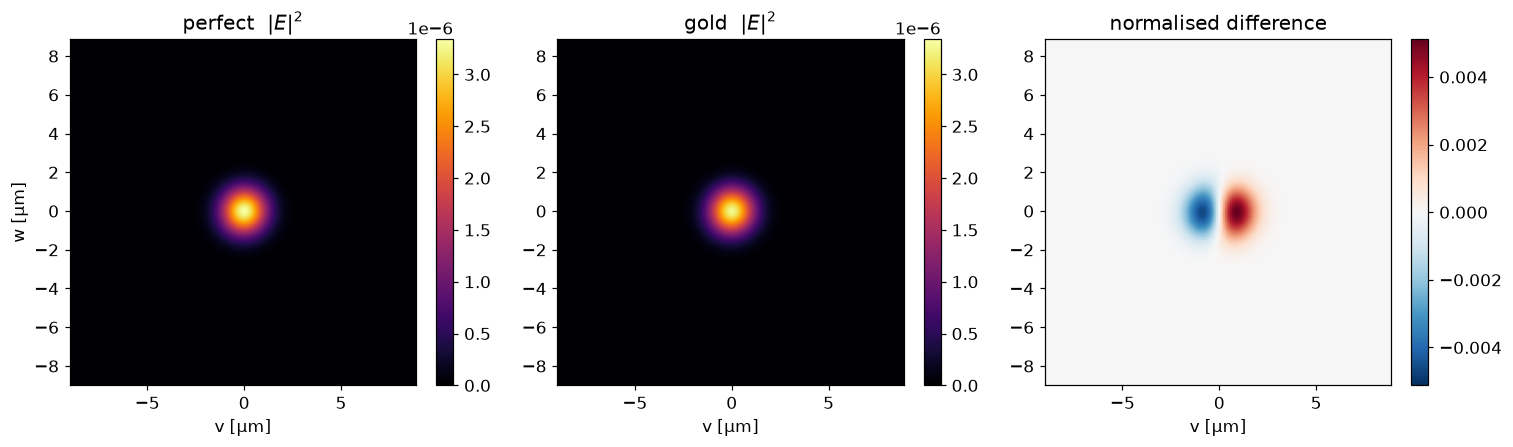

throughput (gold/perfect) = 0.9772   peak ratio = 0.9768   max|ΔI_norm| = 0.0051


In [7]:
op = oap_focus('perfect', pol=(1,1,0)); og = oap_focus('gold', pol=(1,1,0))
Ip = np.abs(op['Ex'])**2+np.abs(op['Ey'])**2+np.abs(op['Ez'])**2
Ig = np.abs(og['Ex'])**2+np.abs(og['Ey'])**2+np.abs(og['Ez'])**2
vax = op['vax']; ext = [vax[0]*1e6, vax[-1]*1e6]*2
vmax = Ip.max()

fig, ax = plt.subplots(1, 3, figsize=(14, 4.0))
for a_, dat, ttl in [(ax[0], Ip, 'perfect  $|E|^2$'), (ax[1], Ig, 'gold  $|E|^2$')]:
    im = a_.imshow(dat, origin='lower', extent=ext, cmap='inferno', vmin=0, vmax=vmax)
    a_.set_title(ttl); a_.set_xlabel('v [µm]'); plt.colorbar(im, ax=a_, fraction=.046)
d = Ig/Ig.max() - Ip/Ip.max()
im = ax[2].imshow(d, origin='lower', extent=ext, cmap='RdBu_r',
                  vmin=-np.abs(d).max(), vmax=np.abs(d).max())
ax[2].set_title('normalised difference'); ax[2].set_xlabel('v [µm]')
plt.colorbar(im, ax=ax[2], fraction=.046)
ax[0].set_ylabel('w [µm]'); plt.tight_layout(); plt.show()
print(f"throughput (gold/perfect) = {Ig.sum()/Ip.sum():.4f}   "
      f"peak ratio = {Ig.max()/Ip.max():.4f}   max|ΔI_norm| = {np.abs(d).max():.4f}")

## 6. Comparison 2 — polarization (where they really differ)

Circular Stokes parameter on the transverse pair $(E_y,E_z)$ (intensity-weighted, so
it is dominated by the bright focal spot rather than the dim wings):
$$
S_0=|E_y|^2+|E_z|^2,\qquad S_3=2\,\mathrm{Im}(E_y E_z^{*}),\qquad \text{ellipticity}=S_3/S_0 .
$$
A perfect mirror keeps the 45° input **linear** ($S_3\!\approx\!0$ at the focus); gold's
$s$–$p$ phase split makes the focus **elliptical** ($S_3/S_0\approx0.2$). We report both
the peak-pixel and the intensity-weighted ellipticity.

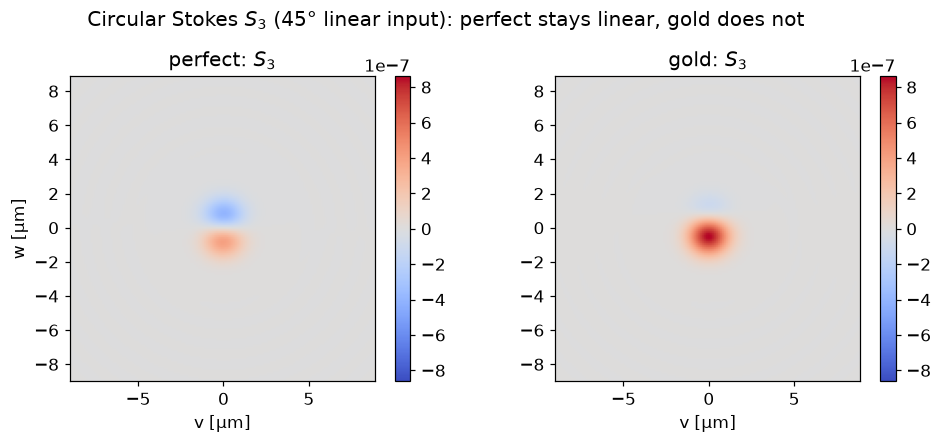

peak ellipticity  S3/S0 :  perfect=+0.000   gold=+0.202
net (∑S3/∑S0)          :  perfect=-0.000   gold=+0.201
=> gold turns the 45° linear input into a partly circular (elliptical) focus.


In [8]:
def stokes(o):
    Ey, Ez = o['Ey'], o['Ez']
    S0 = np.abs(Ey)**2 + np.abs(Ez)**2
    S3 = 2*np.imag(Ey*np.conj(Ez))            # circular Stokes (intensity-weighted)
    return S0, S3

S0p, S3p = stokes(op); S0g, S3g = stokes(og)
lim = np.abs(S3g).max()
fig, ax = plt.subplots(1, 2, figsize=(9.2, 4.0))
for a_, dat, ttl in [(ax[0], S3p, 'perfect: $S_3$'), (ax[1], S3g, 'gold: $S_3$')]:
    im = a_.imshow(dat, origin='lower', extent=ext, cmap='coolwarm', vmin=-lim, vmax=lim)
    a_.set_title(ttl); a_.set_xlabel('v [µm]'); plt.colorbar(im, ax=a_, fraction=.046)
ax[0].set_ylabel('w [µm]')
plt.suptitle('Circular Stokes $S_3$ (45° linear input): perfect stays linear, gold does not')
plt.tight_layout(); plt.show()

# metrics at the focal peak and intensity-weighted over the spot
Itot_p = S0p + np.abs(op['Ex'])**2
iy, ix = np.unravel_index(np.argmax(Itot_p), Itot_p.shape)
print(f"peak ellipticity  S3/S0 :  perfect={S3p[iy,ix]/S0p[iy,ix]:+.3f}   gold={S3g[iy,ix]/S0g[iy,ix]:+.3f}")
print(f"net (∑S3/∑S0)          :  perfect={S3p.sum()/S0p.sum():+.3f}   gold={S3g.sum()/S0g.sum():+.3f}")
print("=> gold turns the 45° linear input into a partly circular (elliptical) focus.")

## 7. Summary table over input polarizations

Pure $s$ ($\hat{\mathbf y}$) sees only $r_s$ → a small uniform dimming, no polarization
change. Pure $p$ ($\hat{\mathbf x}$) sees only $r_p$. Only a **mixed** input (45°,
circular) reveals gold's distinctive $s$–$p$ signature.

In [9]:
def metrics(pol):
    op = oap_focus('perfect', pol=pol); og = oap_focus('gold', pol=pol)
    Ip = np.abs(op['Ex'])**2+np.abs(op['Ey'])**2+np.abs(op['Ez'])**2
    Ig = np.abs(og['Ex'])**2+np.abs(og['Ey'])**2+np.abs(og['Ez'])**2
    S0p, S3p = stokes(op); S0g, S3g = stokes(og)
    return Ig.sum()/Ip.sum(), S3p.sum()/S0p.sum(), S3g.sum()/S0g.sum()

print(f"{'input pol':16s}{'throughput':>12s}{'net S3/S0 perf':>16s}{'net S3/S0 gold':>16s}")
for pol, name in [((0,1,0),'y  (pure s)'), ((1,0,0),'x  (pure p)'),
                  ((1,1,0),'45° (s+p)'), ((1,1j,0),'circular')]:
    thr, ep, eg = metrics(pol)
    print(f"{name:16s}{thr:12.4f}{ep:16.3f}{eg:16.3f}")

input pol         throughput  net S3/S0 perf  net S3/S0 gold
y  (pure s)           0.9846          -0.000          -0.000
x  (pure p)           0.9698          -0.000          -0.000
45° (s+p)             0.9772          -0.000           0.201
circular              0.9772          -1.000          -0.978


## Summary

* The **vectorial Fresnel reflection** $\mathbf E_r=r_s(\mathbf E_i\!\cdot\!\hat{\mathbf s})\hat{\mathbf s}+r_p(\mathbf E_i\!\cdot\!\hat{\mathbf p}_i)\hat{\mathbf p}_r$
  is implemented and reduces to the ideal mirror in the perfect-conductor limit
  (checked to $2\times10^{-15}$).
* For near-IR gold the **intensity** images are nearly identical — gold is ~2% dimmer
  with sub-percent shape change. If you only care about the PSF intensity, the perfect
  mirror is a fine model here.
* The real difference is **polarization**: at ~45° incidence the $s$–$p$ phase split
  ellipticises a mixed-polarization focus ($S_3/S_0$ up to ~0.2), while a perfect
  mirror keeps it linear. This matters for polarization-sensitive experiments
  (vector beams, vortices, polarimetry).

**Caveats.** (1) `N_AU` is an approximate literature value — use your own tabulated /
ellipsometry data; the phase split (hence the ellipticity) scales with it. (2) Ideal
smooth surface — no roughness, oxide, or protective overcoat, all of which shift
$r_s,r_p$. (3) The $s/p$ phase has a convention offset at normal incidence (handled by
referencing to $0°$); only relative phase is physical. (4) Still a single reflection;
a real beamline with several gold optics multiplies these polarization effects.